In [11]:
# The purpose of this notebook is to inspect the distribution of the candidate predictions uncertainty
# This will be useful in understanding how we should go about which formulas to actually make

In [ ]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)


# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
df = df[formula_cols + measured_target_cols].copy()
df[formula_cols] = df[formula_cols].fillna(0.0)
df[measured_target_cols] = df[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(df) == 25, (
    f"Expected the 25 original samples; found {len(df)}."
)
display(df)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.770000
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.120000
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.250000
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.330000
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.580000
5,8,3.0,0.0,0.0,0.0,0.202000,111.044347,27.400000
6,5,0.0,0.0,0.0,0.0,0.298930,56.958538,36.614852
7,5,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5,0.0,1.0,0.0,0.0,0.355557,44.308895,43.766577
9,5,0.0,2.0,0.0,0.0,0.358055,43.326301,44.186536


In [13]:
# generate candidate formulas, they are stored in candidate_set

# Formula constraints:
# - TEM: 5-8%.
# - Each chain extender (Joncryl, NC513, PEG-DE, NGDE): 0.7-3% when included; 0% when omitted.
# NC513 .7-5%
# - Combined chain extender amount: no more than 6%.
# - Generate 100,000 valid candidate formulas.
import numpy as np
import pandas as pd
candidate_count = 200
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]
feature_cols = ["TEM", *chain_extender_cols]
rng = np.random.default_rng(42)

candidate_chunks = []
collected = 0
while collected < candidate_count:
    batch_size = max(200, 2 * (candidate_count - collected))
    active_counts = rng.integers(1, len(chain_extender_cols) + 1, size=batch_size)
    active_order = rng.random((batch_size, len(chain_extender_cols))).argsort(axis=1)
    active_mask = active_order < active_counts[:, None]

    extender_amounts = rng.uniform(
        0.7, 3.0, size=(batch_size, len(chain_extender_cols))
    )
    nc513_idx = chain_extender_cols.index("NC513")
    extender_amounts[:, nc513_idx] = rng.uniform(0.7, 5.0, size=batch_size)

    extender_amounts = np.where(active_mask, extender_amounts, 0.0)

    valid_mask = extender_amounts.sum(axis=1) <= 6.0
    valid_batch = extender_amounts[valid_mask]
    candidate_chunks.append(valid_batch)
    collected += len(valid_batch)

extender_values = np.concatenate(candidate_chunks, axis=0)[:candidate_count]
candidate_set = pd.DataFrame(extender_values, columns=chain_extender_cols)
candidate_set.insert(0, "TEM", rng.uniform(5.0, 8.0, size=candidate_count))
candidate_set = candidate_set[feature_cols]

# Confirm the generated formulas satisfy every requested bound.
assert len(candidate_set) == candidate_count
assert candidate_set["TEM"].between(5.0, 8.0).all()
assert candidate_set[chain_extender_cols].sum(axis=1).le(6.0).all()

for col in chain_extender_cols:
    active = candidate_set[col].ne(0)
    upper_bound = 5.0 if col == "NC513" else 3.0
    assert candidate_set.loc[active, col].between(0.7, upper_bound).all()

print(f"Generated {len(candidate_set):,} valid candidate formulas.")
print(candidate_set.head())
print("Maximum total chain extender:", candidate_set[chain_extender_cols].sum(axis=1).max())

Generated 200 valid candidate formulas.
        TEM   Joncryl     NC513    PEG-DE      NGDE
0  5.046742  0.000000  0.000000  1.010684  0.000000
1  5.619889  2.408685  0.000000  0.000000  1.955336
2  5.937163  0.000000  2.918365  0.000000  0.000000
3  5.534621  0.000000  0.000000  0.000000  0.918931
4  5.060433  0.000000  0.000000  2.469258  0.000000
Maximum total chain extender: 5.986980824561686


In [14]:
# load the gpr_models
import joblib
from pathlib import Path

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
models_dir = project_root / "models"
gpr_models = joblib.load(models_dir / "gpr_models.joblib")

# Get predictions and standard deviations for these formulas from the GPR models

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
X_candidates = candidate_set.loc[:, feature_cols]

batch_size = 5_000
prediction_columns = {}

for name, model in gpr_models.items():
    mean_batches = []
    std_batches = []

    for start in range(0, len(X_candidates), batch_size):
        means, stds = model.predict(
            X_candidates.iloc[start : start + batch_size],
            return_std=True,
        )
        mean_batches.append(means)
        std_batches.append(stds)

    prediction_columns[f"pred_{name}"] = np.concatenate(mean_batches)
    prediction_columns[f"std_{name}"] = np.concatenate(std_batches)

predictions = pd.DataFrame(prediction_columns, index=candidate_set.index)
candidate_predictions = pd.concat([candidate_set, predictions], axis=1)

display(candidate_predictions.head())

,TEM,Joncryl,NC513,PEG-DE,NGDE,pred_Avg_Density_g_cm3,std_Avg_Density_g_cm3,pred_24h_avg_pct absorption,std_24h_avg_pct absorption,pred_24h_avg_pct_retention,std_24h_avg_pct_retention
0,5.046742,0.000000,0.000000,1.010684,0.000000,0.301524,0.014862,168.432830,45.387122,35.661506,9.364520
1,5.619889,2.408685,0.000000,0.000000,1.955336,0.215211,0.063813,40.286857,40.373955,30.900955,15.245824
2,5.937163,0.000000,2.918365,0.000000,0.000000,0.245224,0.042891,73.333387,19.824922,33.145253,11.534403
3,5.534621,0.000000,0.000000,0.000000,0.918931,0.287277,0.035867,53.898751,20.298062,36.386841,8.476659
4,5.060433,0.000000,0.000000,2.469258,0.000000,0.301457,0.014992,210.024276,68.241845,32.412528,14.308187


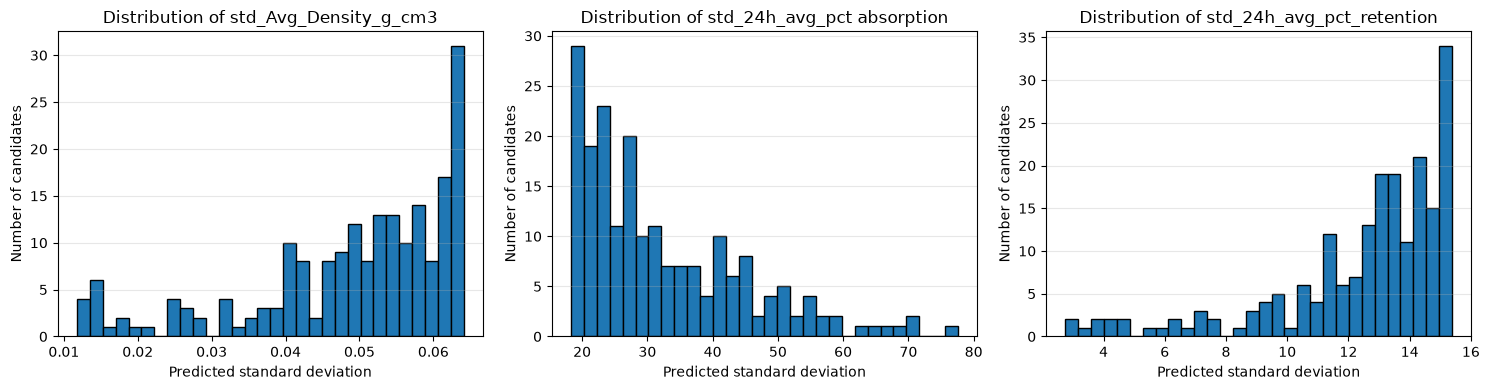

In [15]:
# print the distribution of std for the model predictions for each of the 3 properties

import matplotlib.pyplot as plt

std_cols = [col for col in candidate_predictions.columns if col.startswith("std_")]

fig, axes = plt.subplots(1, len(std_cols), figsize=(5 * len(std_cols), 4))
axes = [axes] if len(std_cols) == 1 else axes

for ax, col in zip(axes, std_cols):
    ax.hist(candidate_predictions[col].dropna(), bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Predicted standard deviation")
    ax.set_ylabel("Number of candidates")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

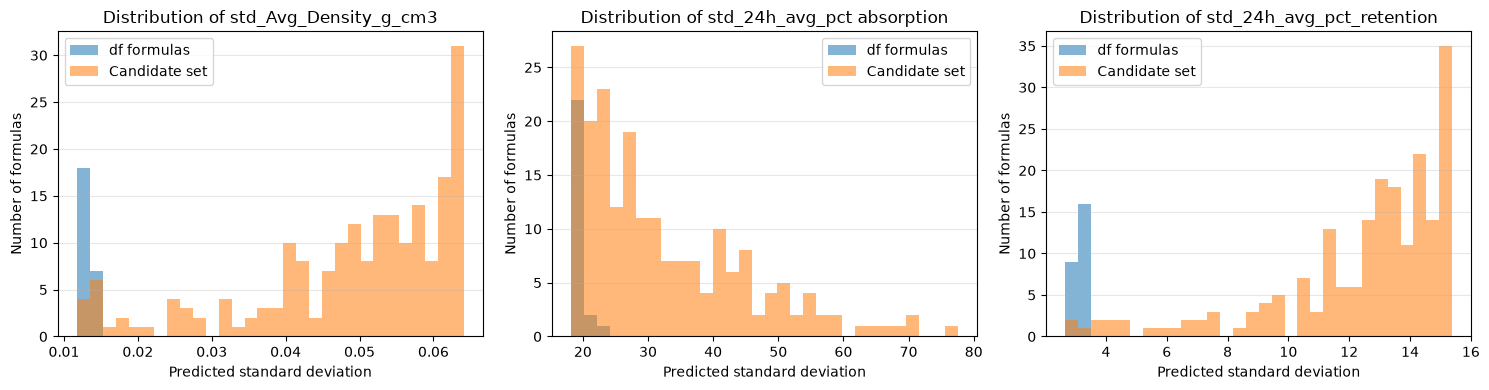

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention,std_Avg_Density_g_cm3,std_24h_avg_pct absorption,std_24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.77,0.011755,19.232708,2.907867
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.12,0.013377,18.276025,3.239489
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.25,0.012106,18.292458,3.171415
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.33,0.013799,18.500286,3.276503
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.58,0.014707,18.883451,3.324471


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
chain_extender_cols = ["Joncryl", "NC513", "PEG-DE", "NGDE"]

# Prepare formulas from df. Missing TEM rows cannot be predicted.
df_formulas = df.dropna(subset=["TEM"]).copy()
X_df = df_formulas.loc[:, feature_cols].copy()
X_df[chain_extender_cols] = X_df[chain_extender_cols].fillna(0.0)

# Get the model's predicted standard deviation for each formula.
df_std_columns = {}
batch_size = 5_000

for name, model in gpr_models.items():
    std_batches = []

    for start in range(0, len(X_df), batch_size):
        _, stds = model.predict(
            X_df.iloc[start : start + batch_size],
            return_std=True,
        )
        std_batches.append(stds)

    df_std_columns[f"std_{name}"] = np.concatenate(std_batches)

df_predictions = pd.concat(
    [
        df_formulas,
        pd.DataFrame(df_std_columns, index=df_formulas.index),
    ],
    axis=1,
)

# Overlay df and candidate-set standard-deviation distributions.
std_cols = [f"std_{name}" for name in gpr_models]

fig, axes = plt.subplots(1, len(std_cols), figsize=(5 * len(std_cols), 4))
axes = np.atleast_1d(axes)

for ax, col in zip(axes, std_cols):
    df_std = df_predictions[col].dropna().to_numpy()
    candidate_std = candidate_predictions[col].dropna().to_numpy()

    combined = np.concatenate([df_std, candidate_std])
    bins = np.histogram_bin_edges(combined, bins=30)
    
    ax.hist(df_std, bins=bins, alpha=0.55, label="df formulas")
    ax.hist(candidate_std, bins=bins, alpha=0.55, label="Candidate set")

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Predicted standard deviation")
    ax.set_ylabel("Number of formulas")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(df_predictions.head())